# Model C_8: Learned temporal decay (CNN) dengan late fusion

**Pertanyaan.** Di C6, berita 20 hari terakhir dirangkum dengan bobot waktu yang **ditetapkan**:
`0.5^(lag / half_life)`. Apakah lebih baik kalau model **mempelajari sendiri** seberapa penting tiap hari
yang lalu? (1b.v: agregasi fitur melalui sliding window temporal.)

**Fitur sama dengan C6, arsitektur berbeda.** C8 memakai fitur harian dari satu varian C6 yang dikunci
(`C6_PIN`). Karena fiturnya identik, perbedaan skor dengan baris C6 murni berasal dari cara menimbang waktu:

| Baris | Fitur | Agregasi waktu |
|---|---|---|
| `C6_<pin>_HGB` | C6 | decay eksponensial tetap + HGB |
| **`C8_C`** | C6 | **kurva bobot yang dipelajari** (CNN) |

**Arsitektur (late fusion, tugas 2.a.ii)**

```
teks  (20 hari × fitur C6) ──► konvolusi kurva-bobot (1 kurva per kelompok fitur) ──► rata-rata berbobot ──► head teks ──► logit_teks ─┐
                                                                                                                                       ├─► fusion (a·logit_teks + b·logit_harga + c) ──► P(naik)
harga (11 fitur, hari t) ─────────────────────────────────────────────────────────────────────────────────────► head harga ─► logit_harga ┘
```

- **Konvolusi kurva-bobot**: konvolusi 1D *depthwise* dengan panjang kernel = panjang jendela (20), dievaluasi
  di hari terakhir. Kernelnya dibuat non-negatif dan berjumlah 1 (softmax), jadi hasilnya tetap rata-rata
  berbobot seperti di C6, hanya bentuk bobotnya yang dipelajari. Satu kurva dipakai bersama per kelompok fitur
  (vektor teks, channel, novelty, volume) → 4 × 20 = 80 parameter kurva, mudah diplot dan sulit overfit.
- **Kurva dimulai dari decay eksponensial C6** (half-life varian yang dikunci), lalu boleh berubah. Penalti
  kehalusan pada selisih kedua log-bobot: kurva eksponensial apa pun (berapa pun half-life-nya) tidak
  dipenalti, yang dicegah hanya bentuk bergerigi.
- **Late fusion**: tiap cabang (teks, harga) menghasilkan logit sendiri dan dilatih juga dengan loss sendiri
  (*auxiliary loss*), jadi keduanya benar-benar sub-model unimodal. Logit digabung dengan bobot yang dipelajari.
  AUC tiap cabang dilaporkan (indikasi, bukan ablasi bersih: cabang teks tetap dilatih bersama cabang harga).

**Satu run** (`n_configs_tried = 1`, hyperparameter tetap). Varian C8_A (harga saja) / C8_B (NLP dasar) untuk
ablasi bersih bisa ditambahkan nanti di `RUNS`.

**Prasyarat**: `05f_C6_weighted_sentences.ipynb` sudah dijalankan (cache embedding di `data/features_c/` dan
`results_c/C6_*.json`). Jalankan dari folder `src/`.

In [1]:
from c_common import *
import c_common
import os, re, time
from functools import lru_cache
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

D, text = load_all()
TITLE, LEAD = "judul_gabungan", "lead_paragraph_gabungan"
DEV = "cuda" if torch.cuda.is_available() else "cpu"

# C6_SMOKE=1: query di-encode dengan encoder palsu (sama seperti smoke test C6) dan hasil ditulis ke folder
# sementara. Hanya untuk menguji pipeline; untuk hasil sebenarnya JANGAN set variabel ini.
SMOKE = os.environ.get("C6_SMOKE") == "1"
if SMOKE:
    import tempfile
    c_common.RESULTS_C = Path(tempfile.mkdtemp(prefix="c8_smoke_")) / "results_c"
    for f in RESULTS_C.glob("C6_*.json"):          # salin hasil C6 supaya pembanding tetap ada
        c_common.RESULTS_C.mkdir(parents=True, exist_ok=True)
        (c_common.RESULTS_C / f.name).write_text(f.read_text())
    print("SMOKE TEST: hasil ke", c_common.RESULTS_C)
print({s: len(d) for s, d in D.items()}, text.shape, "| device:", DEV)

{'train': 825, 'val': 176, 'test': 178} (1202, 5) | device: cuda


## 1. Pengaturan

Bagian **fitur C6** harus sama persis dengan `05f_C6_weighted_sentences.ipynb`. Kalau di sana diubah
(misalnya kalimat `CHANNELS`), salin perubahannya ke sini. Sel cek di bagian 3 akan memberi peringatan kalau
fitur yang dibangun ulang tidak lagi menghasilkan skor C6 yang tersimpan.

In [2]:
C6_PIN = "nov"     #varian C6 yang fiturnya dipakai: varian salience terbaik di validation (base = tanpa bobot isi)

#fitur C6 (HARUS sama dengan 05f_C6_weighted_sentences)
SCORER_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
HF_CACHE = None
WINDOW = 20
N_COMP = 20
R_SHIFT = 1.0
CHANNELS = {
    "oil_energy": [
        "OPEC+ agrees to cut oil production",
        "Oil prices surge as supply fears grow",
        "Crude oil prices plunge on weak demand",
        "Shipping through the Strait of Hormuz is disrupted",
        "Sanctions hit Russian oil and gas exports",
    ],
    "fed_us_rates": [
        "The Federal Reserve raises interest rates",
        "Fed signals interest rate cuts as inflation cools",
        "US inflation comes in hotter than expected",
        "Treasury yields jump after a strong jobs report",
        "Powell says the Fed will keep rates higher for longer",
    ],
    "risk_off_conflict": [
        "Military strikes escalate the conflict in the Middle East",
        "Russia launches a new offensive in Ukraine",
        "Global stocks tumble as investors flee to safe havens",
        "Tensions rise over Taiwan as China holds military drills",
        "Ceasefire agreement eases fears of a wider war",
    ],
    "china_trade": [
        "The US imposes new tariffs on Chinese imports",
        "China retaliates in the escalating trade war",
        "China's economy slows as factory activity contracts",
        "Beijing announces stimulus to support growth",
        "Washington tightens export controls on chips to China",
    ],
    "indonesia_em": [
        "Bank Indonesia holds its benchmark interest rate",
        "The rupiah weakens against the US dollar",
        "Foreign investors pull money out of emerging markets",
        "Indonesia's economy grows faster than expected",
        "Emerging market currencies slide as the dollar strengthens",
    ],
    "commodities": [
        "Coal prices rise on strong demand from Asia",
        "Palm oil prices fall amid rising stockpiles",
        "Nickel prices jump after export restrictions",
        "Commodity prices rally on hopes of Chinese demand",
        "Gold hits a record high as investors seek safety",
    ],
}
NOISE = [
    "The team won the championship game",
    "A celebrity announces a new movie role",
    "Tips for a healthy diet and better sleep",
    "Local police investigate a shooting",
    "A new smartphone is released with a better camera",
    "Lawmakers debate changes to Social Security benefits",
]
CH = list(CHANNELS)

#model C8 (tetap, tidak dituning)
GROUPS = {"vektor": ("v_",), "channel": ("ch_",), "novelty": ("nov_",)}  
SMOOTH = 1e-1     
AUX = 0.5          
DROP = 0.2
LR, WD = 3e-3, 1e-2
THETA_LR = 3e-2   #learning rate kurva lebih besar: early stopping berhenti cepat, kurva harus sempat berubah
EPOCHS, PATIENCE, BATCH = 200, 15, 32
SEEDS = [0, 1, 2, 3, 4]

_rec = json.loads((RESULTS_C / f"C6_{C6_PIN}_HGB.json").read_text())
C6_CFG = _rec["c6_config"]  
print("fitur C6:", C6_PIN, C6_CFG)

fitur C6: nov {'tau': 1.0, 'k': 5, 'half': 2}


## 2. Fitur harian C6 (dibangun ulang dari cache embedding)

Kode di bawah disalin dari C6: tabel kalimat, skor channel, relevansi, novelty, dan `day_table`.

In [3]:
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'“])")


def build_sentence_table(text_df):
    rows, art_id = [], 0
    for pos, (t, l) in enumerate(zip(text_df[TITLE].fillna(""), text_df[LEAD].fillna(""))):
        titles = [x.strip() for x in t.split(" | ") if x.strip()]
        if not titles:
            continue
        leads = [x.strip() for x in l.split(" | ")]
        if len(leads) != len(titles):
            leads = [""] * len(titles)
        for ti, li in zip(titles, leads):
            sents, seen = [], set()
            for s in [ti] + [x.strip() for x in SENT_SPLIT.split(li)]:
                key = s.lower().strip(" .")
                if len(s.split()) >= 3 and key not in seen:
                    seen.add(key)
                    sents.append(s)
            if not sents:
                sents = [ti]
            rows += [(pos, art_id, j, s) for j, s in enumerate(sents)]
            art_id += 1
    S = pd.DataFrame(rows, columns=["day", "art", "sent_no", "sentence"])
    S["date"] = text_df.index[S["day"].values]
    split_of = {d: s for s in D for d in D[s]["date"]}
    S["split"] = S["date"].map(split_of).fillna("warmup")
    return S


S = build_sentence_table(text)
E_sc = np.load(FEATURES_C / "c6_scorer_minilm.npy")
E_rep = np.load(FEATURES_C / "c6_finbert_sent_cls.npy")
assert len(E_sc) == len(S) == len(E_rep), "cache C6 tidak cocok dengan tabel kalimat: jalankan ulang 05f"


def encode_queries(texts):
    if SMOKE:
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.decomposition import TruncatedSVD
        vec = TfidfVectorizer(min_df=2, ngram_range=(1, 2), max_features=50000, sublinear_tf=True)
        svd = TruncatedSVD(64, random_state=SEED).fit(vec.fit_transform(S["sentence"]))
        Z = svd.transform(vec.transform(texts))
        return (Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-9)).astype("float32")
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(SCORER_MODEL, cache_folder=HF_CACHE, device=DEV)
    return m.encode(texts, normalize_embeddings=True).astype("float32")


q_texts = [q for c in CH for q in CHANNELS[c]] + NOISE
q_owner = np.array([c for c in CH for _ in CHANNELS[c]] + ["noise"] * len(NOISE))
sim = E_sc @ encode_queries(q_texts).T
RAW = np.column_stack([sim[:, q_owner == c].max(1) for c in CH + ["noise"]])
is_tr = (S["split"] == "train").values
Z = (RAW - RAW[is_tr].mean(0)) / (RAW[is_tr].std(0) + 1e-8)
P = 1 / (1 + np.exp(-(Z - R_SHIFT)))
Z_ch, P_ch, P_noise = Z[:, :len(CH)], P[:, :len(CH)], P[:, -1]
S["relevance"] = P_ch.max(1) * (1 - P_noise)


def channel_split(tau):
    e = np.exp((Z_ch - Z_ch.max(1, keepdims=True)) / tau)
    return e / e.sum(1, keepdims=True)


def novelty(E, day, k):
    nov = np.ones(len(E), dtype="float32")
    by_day = {d: np.where(day == d)[0] for d in np.unique(day)}
    for d, ix in by_day.items():
        prev = [by_day[p] for p in range(d - k, d) if p in by_day]
        if prev:
            pv = np.concatenate(prev)
            nov[ix] = 1 - (E[ix] @ E[pv].T).max(1)
    return np.clip(nov, 0, 1)


USES = {"base": (False, False, False, False), "rel": (True, False, False, False),
        "chan": (True, True, False, False), "nov": (True, True, True, False), "hier": (True, True, True, True)}
N_DAYS, DAY, ART = len(text), S["day"].values, S["art"].values
tr_dates = D["train"]["date"]


def group_wmean(keys, vecs, w):
    num = pd.DataFrame(vecs * w[:, None]).groupby(keys).sum()
    return num.div(pd.Series(w).groupby(keys).sum(), axis=0)


def to_days(df_by_day, n_cols):
    out = np.zeros((N_DAYS, n_cols), dtype="float64")
    out[df_by_day.index.values] = df_by_day.values
    return out


@lru_cache(maxsize=None)
def day_table(variant, tau=None, k=None):
    use_rel, use_chan, use_nov, hier = USES[variant]
    w = S["relevance"].values.copy() if use_rel else np.ones(len(S))
    nov = novelty(E_sc, DAY, k) if use_nov else None
    if use_nov:
        w = w * nov
    w = w + 1e-6
    if hier:
        art_vec = group_wmean(ART, E_rep, w)
        art_w = pd.Series(w).groupby(ART).max().loc[art_vec.index].values
        art_day = pd.Series(DAY).groupby(ART).first().loc[art_vec.index].values
        day_vec = group_wmean(art_day, art_vec.values, art_w)
    else:
        day_vec = group_wmean(DAY, E_rep, w)
    V = to_days(day_vec, E_rep.shape[1])
    has = np.zeros(N_DAYS, bool)
    has[np.unique(DAY)] = True
    tr_pos = text.index.get_indexer(tr_dates)
    tr_pos = tr_pos[has[tr_pos]]
    Vp = PCA(n_components=N_COMP, random_state=SEED).fit(V[tr_pos]).transform(V)
    Vp[~has] = 0
    F = pd.DataFrame(Vp, index=text.index, columns=[f"v_{i}" for i in range(N_COMP)])
    if use_chan:
        wc = w[:, None] * channel_split(tau)
        F[[f"ch_{c}_mass" for c in CH]] = np.log1p(to_days(pd.DataFrame(wc).groupby(DAY).sum(), len(CH)))
        F[[f"ch_{c}_max" for c in CH]] = to_days(pd.DataFrame(wc).groupby(DAY).max(), len(CH))
    if use_nov:
        nv = pd.Series(nov)
        F["nov_mean"] = to_days(nv.groupby(DAY).mean().to_frame(), 1)[:, 0]
        F["nov_max"] = to_days(nv.groupby(DAY).max().to_frame(), 1)[:, 0]
        art_nov = nv.groupby(ART).mean()
        art_day = pd.Series(DAY).groupby(ART).first()
        thr = art_nov[(S.groupby("art")["split"].first() == "train").values].median()
        F["nov_share_new"] = to_days((art_nov > thr).groupby(art_day.values).mean().to_frame(), 1)[:, 0]
    F["has_news"] = has.astype(float)
    F["log_n_art"] = np.log1p(to_days(pd.Series(ART).groupby(DAY).nunique().to_frame(), 1)[:, 0])
    return F


COND_PREFIX = ("v_", "nov_")


def window_decay(F, half, window=WINDOW):
    cond = [c for c in F.columns if c.startswith(COND_PREFIX)]
    inten = [c for c in F.columns if c not in cond]
    Xc, Xi, has = F[cond].values, F[inten].values, F["has_news"].values
    n = len(F)
    num_c, den_c = np.zeros_like(Xc), np.zeros(n)
    num_i, den_i = np.zeros_like(Xi), np.zeros(n)
    for L in range(window):
        wl = 0.5 ** (L / half)
        num_c[L:] += wl * has[:n - L, None] * Xc[:n - L]
        den_c[L:] += wl * has[:n - L]
        num_i[L:] += wl * Xi[:n - L]
        den_i[L:] += wl
    out = pd.DataFrame(np.where(den_c[:, None] > 0, num_c / np.maximum(den_c, 1e-12)[:, None], 0.0),
                       index=F.index, columns=["dk_" + c for c in cond])
    out[["dk_" + c for c in inten]] = num_i / den_i[:, None]
    out["dk_news_frac"] = den_c / den_i
    return out


F = day_table(C6_PIN, C6_CFG["tau"], C6_CFG["k"])
print(F.shape[1], "fitur harian:", list(F.columns[:3]), "...", list(F.columns[-4:]))

W1120 14:41:41.216000 19112 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

37 fitur harian: ['v_0', 'v_1', 'v_2'] ... ['nov_max', 'nov_share_new', 'has_news', 'log_n_art']


## 3. Cek: fitur yang dibangun ulang = fitur C6

Fitur decay C6 dibangun ulang lalu HGB dilatih dengan hyperparameter C6 yang tersimpan. Kalau skornya sama
dengan `results_c/C6_<pin>_HGB.json`, fitur C8 identik dengan C6.

In [4]:
W = window_decay(F, C6_CFG["half"])
Dx = {s: D[s].merge(W, left_on="date", right_index=True, how="left").fillna(0) for s in D}
cols = list(W.columns)
prob = make_model("HGB", _rec["best_params"]).fit(Dx["train"][PRICE + cols], Dx["train"]["target"]) \
                                             .predict_proba(Dx["val"][PRICE + cols])[:, 1]
f1 = metrics(Dx["val"]["target"], (prob >= 0.5).astype(int), prob)["F1_macro"]
if abs(f1 - _rec["val"]["F1_macro"]) < 1e-6:
    print(f"OK: fitur identik dengan C6 (F1 val {f1:.3f})")
else:
    print(f"PERINGATAN: F1 val {f1:.3f} != C6 tersimpan {_rec['val']['F1_macro']:.3f}. "
          "Fitur berbeda dari C6 (pengaturan tidak sama, atau cache/hasil C6 dari run lain).")

OK: fitur identik dengan C6 (F1 val 0.545)


## 4. Data urutan 20 hari

Fitur distandardisasi dengan statistik train. Fitur *kondisional* (vektor teks, novelty) hanya dihitung pada
hari yang ada beritanya (seperti C6), jadi hari tanpa berita di-mask. Fitur *intensitas* (channel, volume)
memakai semua hari.

In [5]:
cols_txt = list(F.columns)
cond = np.array([c.startswith(COND_PREFIX) for c in cols_txt])
group_names = list(GROUPS) + ["volume"]
group_of = np.array([next((i for i, (g, pre) in enumerate(GROUPS.items()) if c.startswith(pre)), len(GROUPS))
                     for c in cols_txt])
group_names = [g for i, g in enumerate(group_names) if (group_of == i).any()]   # buang kelompok kosong
group_of = np.unique(group_of, return_inverse=True)[1]
print({g: int((group_of == i).sum()) for i, g in enumerate(group_names)}, "fitur per kelompok kurva")

has = F["has_news"].values.astype(bool)
tr_pos = text.index.get_indexer(tr_dates)
Xf = F.values.astype("float64")
mu = np.where(cond, Xf[tr_pos][has[tr_pos]].mean(0), Xf[tr_pos].mean(0))
sd = np.where(cond, Xf[tr_pos][has[tr_pos]].std(0), Xf[tr_pos].std(0)) + 1e-8
Xs = (Xf - mu) / sd
Xs[np.ix_(~has, cond)] = 0                         #hari tanpa berita = 0 (dan di-mask)

pad = WINDOW - 1
Xp = np.vstack([np.zeros((pad, Xs.shape[1])), Xs]).astype("float32")
Hp = np.concatenate([np.zeros(pad), has]).astype("float32")          #mask hari berberita
Vp = np.concatenate([np.zeros(pad), np.ones(len(Xs))]).astype("float32")   #mask hari nyata (bukan padding)
pm, ps = D["train"][PRICE].mean().values, D["train"][PRICE].std().values + 1e-8


def make_data(splits):
    out = {}
    for sp in splits:
        pos = text.index.get_indexer(D[sp]["date"])
        out[sp] = tuple(torch.tensor(a) for a in (
            np.stack([Xp[p:p + WINDOW] for p in pos]),          # (n, 20, F): urutan lama -> baru (hari t terakhir)
            np.stack([Hp[p:p + WINDOW] for p in pos]),
            np.stack([Vp[p:p + WINDOW] for p in pos]),
            ((D[sp][PRICE].values - pm) / ps).astype("float32"),
            D[sp]["target"].values.astype("float32")))
    return out


DATA = make_data(D)
print({s: tuple(DATA[s][0].shape) for s in DATA})

{'vektor': 20, 'channel': 12, 'novelty': 3, 'volume': 2} fitur per kelompok kurva
{'train': (825, 20, 37), 'val': (176, 20, 37), 'test': (178, 20, 37)}


## 5. Model: kurva bobot waktu yang dipelajari + late fusion

In [6]:
class LearnedDecayFusion(nn.Module):
    def __init__(self, group_of, cond, f_price, init_half):
        super().__init__()
        n_groups = int(group_of.max()) + 1
        lags = torch.arange(WINDOW, dtype=torch.float32)
        init = (lags * np.log(0.5) / init_half).repeat(n_groups, 1)     
        self.theta = nn.Parameter(init)                               
        self.register_buffer("group_of", torch.tensor(group_of))
        self.register_buffer("cond", torch.tensor(cond))
        self.drop = nn.Dropout(DROP)
        self.text_head = nn.Linear(len(group_of), 1)
        self.price_head = nn.Linear(f_price, 1)
        self.fuse = nn.Linear(2, 1)
        with torch.no_grad():
            self.fuse.weight.fill_(1.0)
            self.fuse.bias.zero_()

    def curves(self):
        #bobot per lag (lag 0 = hari t), non-negatif dan berjumlah 1
        return torch.softmax(self.theta, dim=1)

    def forward(self, seq, has, valid, price):
        w = self.curves().flip(1)[self.group_of].T            
        mask = torch.where(self.cond, has.unsqueeze(-1), valid.unsqueeze(-1))   
        wm = w * mask
        pooled = (seq * wm).sum(1) / wm.sum(1).clamp_min(1e-6)        
        z_text = self.text_head(self.drop(pooled)).squeeze(1)
        z_price = self.price_head(price).squeeze(1)
        z = self.fuse(torch.stack([z_text, z_price], 1)).squeeze(1)   
        return z, z_text, z_price

    def smooth_penalty(self):
        #selisih kedua: nol untuk kurva eksponensial murni, jadi yang dipenalti hanya bentuk bergerigi
        d2 = self.theta[:, 2:] - 2 * self.theta[:, 1:-1] + self.theta[:, :-2]
        return (d2 ** 2).sum()


def train_c8(data, tr, seed, epochs=None, va=None):
    # epochs=None -> early stopping pada loss fusion di data[va]; kalau tidak, latih tepat `epochs` epoch.
    torch.manual_seed(seed)
    seq, hs, vl, price, y = data[tr]
    net = LearnedDecayFusion(group_of, cond, price.shape[1], C6_CFG["half"])
    rest = [p for n, p in net.named_parameters() if n != "theta"]
    opt = torch.optim.AdamW([{"params": rest, "lr": LR, "weight_decay": WD},
                             {"params": [net.theta], "lr": THETA_LR, "weight_decay": 0.0}])
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y.mean()) / y.mean()))
    g = torch.Generator().manual_seed(seed)
    best_loss, best_state, best_ep, bad = np.inf, None, 0, 0
    for ep in range(1, (epochs or EPOCHS) + 1):
        net.train()
        for ix in torch.randperm(len(y), generator=g).split(BATCH):
            opt.zero_grad()
            z, zt, zp = net(seq[ix], hs[ix], vl[ix], price[ix])
            loss = bce(z, y[ix]) + AUX * (bce(zt, y[ix]) + bce(zp, y[ix])) + SMOOTH * net.smooth_penalty()
            loss.backward()
            opt.step()
        if epochs is None:
            net.eval()
            with torch.no_grad():
                v = bce(net(*data[va][:4])[0], data[va][4]).item()
            if v < best_loss - 1e-4:
                best_loss, best_state, best_ep, bad = v, {a: b.clone() for a, b in net.state_dict().items()}, ep, 0
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
    if best_state is not None:
        net.load_state_dict(best_state)
    return net.eval(), best_ep or epochs


def predict_c8(net, data, sp):
    with torch.no_grad():
        return [torch.sigmoid(z).numpy() for z in net(*data[sp][:4])]   # fusion, teks, harga

## 6. Latih & evaluasi di validation (rata-rata 5 seed)

In [7]:
RUNS = ["C"]   

t0 = time.time()
nets, eps, P_val = [], [], []
for s in SEEDS:
    net, ep = train_c8(DATA, "train", s, va="val")
    nets.append(net)
    eps.append(ep)
    P_val.append(predict_c8(net, DATA, "val"))
p_fuse, p_text, p_price = (np.mean([p[i] for p in P_val], 0) for i in range(3))
y_val = DATA["val"][4].numpy().astype(int)
sc = metrics(y_val, (p_fuse >= 0.5).astype(int), p_fuse)
branch_auc = {"text": float(roc_auc_score(y_val, p_text)), "price": float(roc_auc_score(y_val, p_price))}
CURVES = np.mean([n.curves().detach().numpy() for n in nets], 0)       # (kelompok, lag)
fuse_w = np.mean([n.fuse.weight.detach().numpy()[0] for n in nets], 0)

NAME = "C8_C"
c_common._save(NAME, {
    "name": NAME, "model": "LearnedDecayCNN+LateFusion",
    "n_features": int(len(cols_txt) + len(PRICE)),
    "best_params": dict(smooth=SMOOTH, aux=AUX, dropout=DROP, lr=LR, theta_lr=THETA_LR, weight_decay=WD,
                        epochs=int(round(np.mean(eps))), seeds=SEEDS),
    "val": sc, "n_configs_tried": 1,
    "val_auc_ci95": bootstrap_auc_ci(y_val, p_fuse),
    "branch_val_auc": branch_auc, "fusion_weights": {"text": float(fuse_w[0]), "price": float(fuse_w[1])},
    "c8_config": {"c6_pin": C6_PIN, **C6_CFG, "groups": group_names},
    "learned_curves": {g: CURVES[i].round(5).tolist() for i, g in enumerate(group_names)},
    "note": f"C8 learned decay kernel ({len(group_names)} kurva x {WINDOW} lag) + late fusion, fitur C6_{C6_PIN}",
})
print(f"{NAME} val: " + ", ".join(f"{a}={b:.3f}" for a, b in sc.items()) + f"  ({time.time() - t0:.0f} dtk)")
print("epoch terbaik per seed:", eps)
print("AUC val per cabang:", {a: round(b, 3) for a, b in branch_auc.items()},
      "| bobot fusion (teks, harga):", fuse_w.round(3))

C8_C val: DA=0.477, BalAcc=0.477, F1_macro=0.477, MCC=-0.047, AUC=0.479  (13 dtk)
epoch terbaik per seed: [7, 7, 7, 5, 4]
AUC val per cabang: {'text': 0.474, 'price': 0.487} | bobot fusion (teks, harga): [0.891 0.846]


## 7. Kurva bobot yang dipelajari vs decay eksponensial C6

Setiap garis = berapa besar pengaruh berita *L* hari yang lalu terhadap prediksi untuk satu kelompok fitur
(rata-rata 5 seed). Garis putus-putus abu-abu = decay eksponensial tetap yang dipakai C6 (titik awal
pelatihan). **Lag median** = lag tempat 50% bobot kumulatif tercapai (setara "half-life" efektif).

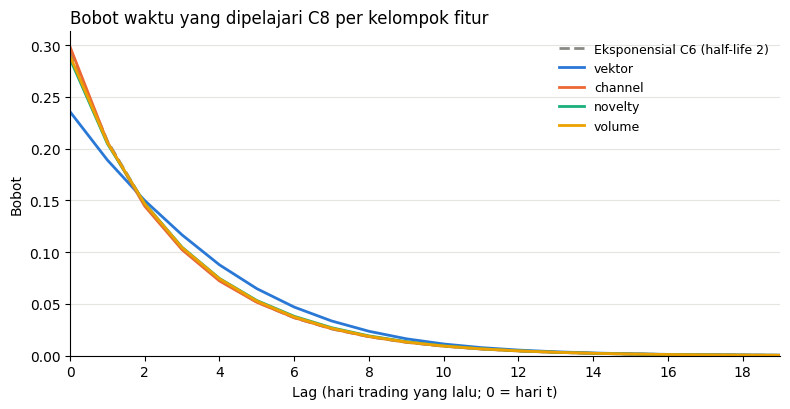

,lag_median,bobot_lag0
eksponensial C6,1,0.293
vektor,2,0.236
channel,1,0.298
novelty,2,0.287
volume,2,0.289


In [8]:
lags = np.arange(WINDOW)
expo = 0.5 ** (lags / C6_CFG["half"])
expo /= expo.sum()
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(lags, expo, color="#8a8a85", lw=2, ls="--", label=f"Eksponensial C6 (half-life {C6_CFG['half']})")
for i, g in enumerate(group_names):
    ax.plot(lags, CURVES[i], color=SERIES[i % len(SERIES)], lw=2, label=g)
ax.set_xlabel("Lag (hari trading yang lalu; 0 = hari t)")
ax.set_ylabel("Bobot")
ax.set_title("Bobot waktu yang dipelajari C8 per kelompok fitur", loc="left")
ax.set_xlim(0, WINDOW - 1)
ax.set_xticks(range(0, WINDOW, 2))
ax.set_ylim(0, None)
ax.grid(axis="y", color="#e5e4df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()


def median_lag(w):
    return int(np.searchsorted(np.cumsum(w) / w.sum(), 0.5))


display(pd.DataFrame({"lag_median": [median_lag(expo)] + [median_lag(c) for c in CURVES],
                      "bobot_lag0": [expo[0]] + list(CURVES[:, 0])},
                     index=["eksponensial C6"] + group_names).round(3))

## 8. Perbandingan dengan C6 (validation)

Fitur sama, agregasi waktu berbeda. Interval AUC yang tumpang tindih jauh berarti perbedaannya belum tentu nyata.

In [9]:
names = [NAME, f"C6_{C6_PIN}_HGB", "C6_base_HGB"]
res = collect_results().set_index("name")
res = res.loc[[n for n in names if n in res.index]].copy()
res["val_auc_ci95"] = [json.loads((c_common.RESULTS_C / f"{n}.json").read_text()).get("val_auc_ci95") for n in res.index]
display(res[["model", "n_features", "n_configs_tried", "val_DA", "val_F1_macro", "val_MCC", "val_AUC", "val_auc_ci95"]].round(3))
_, sc_price, _ = tune("HGB", D, PRICE)
print("REFERENSI harga saja (HGB) val:", {a: round(b, 3) for a, b in sc_price.items()})

,model,n_features,n_configs_tried,val_DA,val_F1_macro,val_MCC,val_AUC,val_auc_ci95
name,,,,,,,,
C8_C,LearnedDecayCNN+LateFusion,48,1,0.477,0.477,-0.047,0.479,"[0.392, 0.573]"
C6_nov_HGB,HGB,49,12,0.545,0.545,0.095,0.515,"[0.436, 0.589]"
C6_base_HGB,HGB,34,3,0.551,0.551,0.102,0.513,"[0.414, 0.595]"


REFERENSI harga saja (HGB) val: {'DA': 0.523, 'BalAcc': 0.521, 'F1_macro': 0.52, 'MCC': 0.042, 'AUC': 0.503}


## 9. Tes akhir (SEKALI)

Hanya kalau C8 dipilih sebagai model akhir berdasarkan validation. Model dilatih ulang pada train+val dengan
jumlah epoch rata-rata dari early stopping, 5 seed, lalu dinilai di test.

In [10]:
RUN_TEST = False

if RUN_TEST:
    rec = json.loads((c_common.RESULTS_C / f"{NAME}.json").read_text())
    assert "test" not in rec, f"{NAME} sudah pernah dites; jangan pilih ulang berdasarkan test."
    trval = {"trval": tuple(torch.cat([DATA["train"][i], DATA["val"][i]]) for i in range(5)), "test": DATA["test"]}
    probs = [predict_c8(train_c8(trval, "trval", s, epochs=rec["best_params"]["epochs"])[0], trval, "test")[0]
             for s in SEEDS]
    p = np.mean(probs, 0)
    y = DATA["test"][4].numpy().astype(int)
    sc_t = metrics(y, (p >= 0.5).astype(int), p)
    ci = bootstrap_auc_ci(y, p)
    c_common._save(NAME, {"test": sc_t, "test_auc_ci95": ci})
    print(f"{NAME} TEST: " + ", ".join(f"{a}={b:.3f}" for a, b in sc_t.items()) + f" | AUC 95% CI {ci}")